In [1]:
%matplotlib inline

In [2]:
import matplotlib.pyplot as plt 
import matplotlib as mpl
plt.style.use('seaborn-v0_8-whitegrid')
import numpy as np
import pandas as pd 

In [3]:
from datetime import datetime
births =pd.read_csv(r"C:\Users\benkh\Python_Handbook\Handbook\data\births.csv")
quartiles = np.percentile(births['births'],[25,50,75])

In [7]:
mu,sig = quartiles[1],0.74*(quartiles[2]-quartiles[0])
births = births.query('(births > @mu-5*@!sig) & (births <@mu+5*@sig)')
births['day'] = births['day'].astype(int)
births.index = pd.to_datetime(10000*births.year+100*births.month + births.day,format='%Y%m%d')
births_by_date = births.pivot_table('births',
                                    [births.index.month,births.index.day])
births_by_date.index = [datetime(2012,month,day)
                        for (month,day) in births_by_date.index]

SyntaxError: invalid syntax (<unknown>, line 1)

<Axes: >

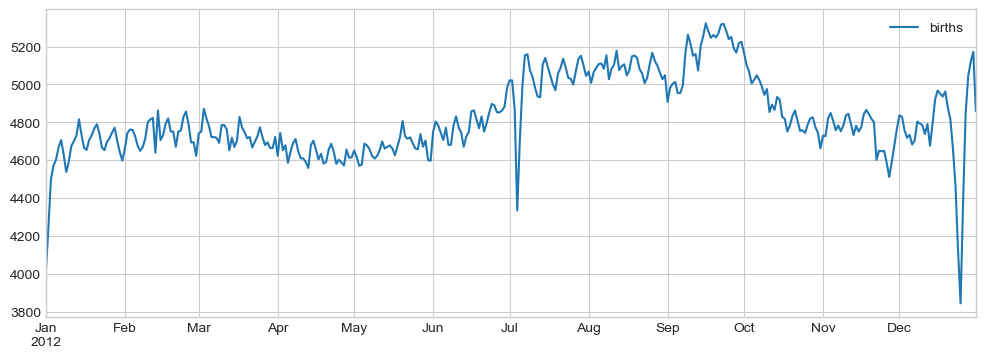

In [8]:
fig,ax = plt.subplots(figsize=(12,4))
births_by_date.plot(ax=ax)

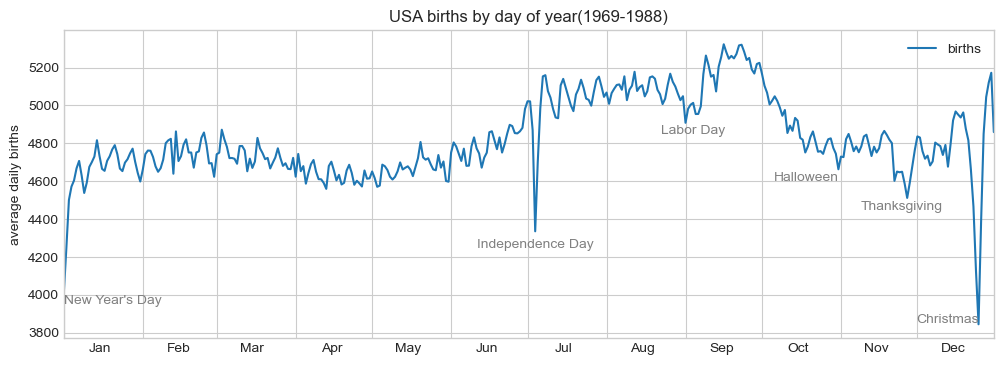

In [10]:
fig,ax = plt.subplots(figsize=(12,4))
births_by_date.plot(ax=ax)
style = dict(size=10,color='gray')
ax.text('2012-1-1',3950,"New Year's Day",**style)
ax.text('2012-7-4',4250,"Independence Day",ha='center',**style)
ax.text('2012-9-4',4850,"Labor Day", ha='center',**style)
ax.text('2012-10-31',4600,"Halloween",ha='right',**style)
ax.text('2012-11-25',4450,"Thanksgiving",ha='center',**style)
ax.text('2012-12-25',3850,"Christmas",ha='right',**style)
ax.set(title ='USA births by day of year(1969-1988)',ylabel='average daily births')
ax.xaxis.set_major_locator(mpl.dates.MonthLocator())
ax.xaxis.set_minor_locator(mpl.dates.MonthLocator(bymonthday=15))
ax.xaxis.set_major_formatter(plt.NullFormatter())
ax.xaxis.set_minor_formatter(mpl.dates.DateFormatter('%h'))

Text(0.2, 0.2, '.Figure:(0.2,0.2)')

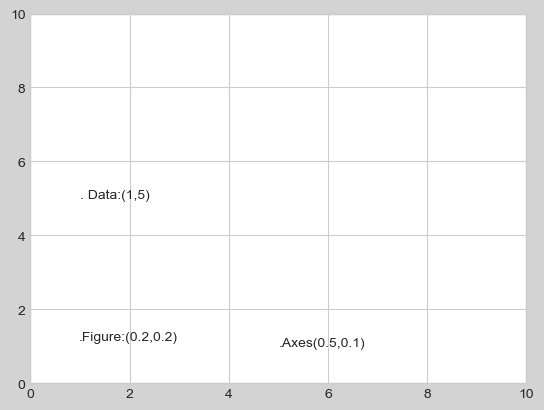

In [12]:
fig, ax = plt.subplots(facecolor='lightgray')
ax.axis([0,10,0,10])
ax.text(1,5,". Data:(1,5)",transform=ax.transData)
ax.text(0.5,0.1,".Axes(0.5,0.1)",transform=ax.transAxes)
ax.text(0.2,0.2,".Figure:(0.2,0.2)",transform=fig.transFigure)

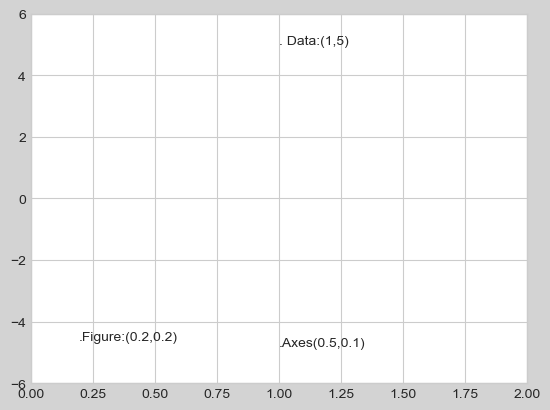

In [13]:
ax.set_xlim(0,2)
ax.set_ylim(-6,6)
fig

Text(2, -6, 'local minumim')

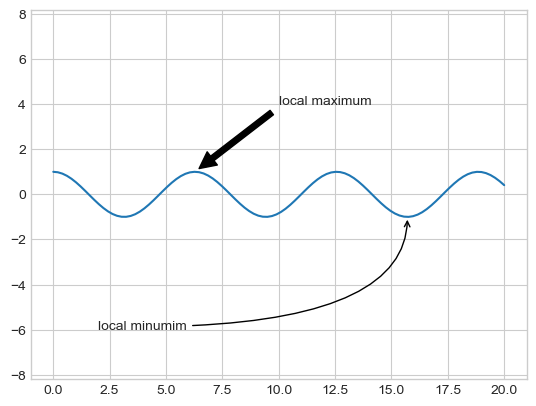

In [14]:
fig,ax = plt.subplots()
x=np.linspace(0,20,100)
ax.plot(x,np.cos(x))
ax.axis('equal')
ax.annotate('local maximum',xy=(6.28,1),xytext=(10,4),
            arrowprops=dict(facecolor='black',shrink=0.05))
ax.annotate('local minumim',xy=(5*np.pi,-1),xytext=(2,-6),
            arrowprops = dict(arrowstyle="->",
                              connectionstyle ="angle3,angleA=0,angleB=-90"))

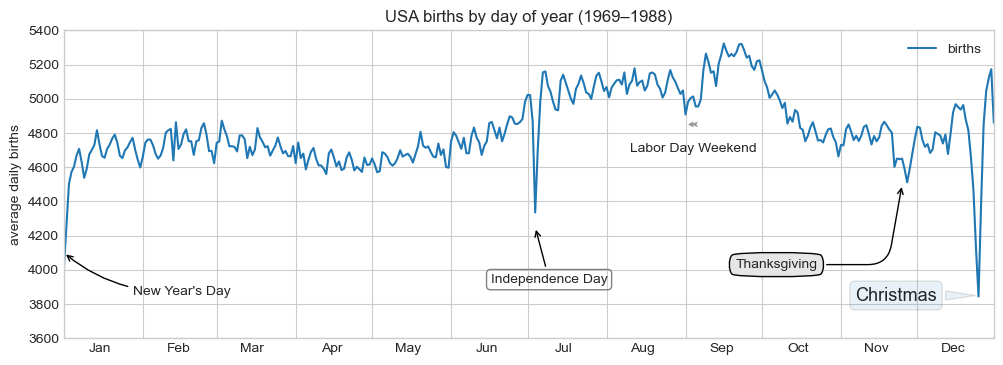

In [17]:
import matplotlib.pyplot as plt
import matplotlib as mpl

fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax)

ax.annotate("New Year's Day",
            xy=('2012-1-1', 4100), xycoords='data',
            xytext=(50, -30), textcoords='offset points',
            arrowprops=dict(arrowstyle="->",
                            connectionstyle="arc3,rad=-0.2"))

ax.annotate("Independence Day",
            xy=('2012-7-4', 4250), xycoords='data',
            xytext=(10, -40), textcoords='offset points',
            ha='center',
            bbox=dict(boxstyle="round", fc="none", ec="gray"),
            arrowprops=dict(arrowstyle="->"))

ax.annotate('Labor Day Weekend',
            xy=('2012-9-4', 4850), xycoords='data',
            ha='center',
            xytext=(0, -20), textcoords='offset points')

ax.annotate('',
            xy=('2012-9-1', 4850), xycoords='data',
            xytext=('2012-9-7', 4850), textcoords='data',
            arrowprops=dict(arrowstyle="fancy",
                            fc="0.6", ec="none",
                            connectionstyle="angle3,angleA=0,angleB=-90"))

ax.annotate('Thanksgiving',
            xy=('2012-11-25', 4500), xycoords='data',
            xytext=(-120, -60), textcoords='offset points',
            bbox=dict(boxstyle="round4,pad=.5", fc="0.9"),
            arrowprops=dict(arrowstyle="->",
                            connectionstyle="angle,angleA=0,angleB=80,rad=20"))

ax.annotate('Christmas',
            xy=('2012-12-25', 3850), xycoords='data',
            xytext=(-30, 0), textcoords='offset points',
            size=13, ha='right', va="center",
            bbox=dict(boxstyle="round", alpha=0.1),
            arrowprops=dict(arrowstyle="wedge,tail_width=0.5",
                            alpha=0.1))

ax.set(title='USA births by day of year (1969–1988)',
       ylabel='average daily births')

ax.xaxis.set_major_locator(mpl.dates.MonthLocator())
ax.xaxis.set_minor_locator(mpl.dates.MonthLocator(bymonthday=15))
ax.xaxis.set_major_formatter(plt.NullFormatter())
ax.xaxis.set_minor_formatter(mpl.dates.DateFormatter('%b'))

ax.set_ylim(3600, 5400)

plt.show()